In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/house_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (30, 5)


,area_sqft,bedrooms,bathrooms,house_age_years,price_lakh
0,550,1,1,15,18
1,600,1,1,10,21
2,650,1,1,8,24
3,700,2,1,18,25
4,750,2,1,12,28


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Column names:
['area_sqft', 'bedrooms', 'bathrooms', 'house_age_years', 'price_lakh']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   area_sqft        30 non-null     int64
 1   bedrooms         30 non-null     int64
 2   bathrooms        30 non-null     int64
 3   house_age_years  30 non-null     int64
 4   price_lakh       30 non-null     int64
dtypes: int64(5)
memory usage: 1.3 KB

Statistical summary:


,area_sqft,bedrooms,bathrooms,house_age_years,price_lakh
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,1345.000000,2.800000,2.400000,7.300000,63.000000
std,553.258373,0.996546,0.968468,3.869866,34.303916
min,550.000000,1.000000,1.000000,2.000000,18.000000
25%,912.500000,2.000000,2.000000,5.000000,36.500000
50%,1275.000000,3.000000,2.000000,6.500000,55.000000
75%,1675.000000,3.000000,3.000000,9.750000,81.000000
max,2600.000000,5.000000,4.000000,18.000000,145.000000


In [3]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
area_sqft          0
bedrooms           0
bathrooms          0
house_age_years    0
price_lakh         0
dtype: int64

Duplicate rows: 0


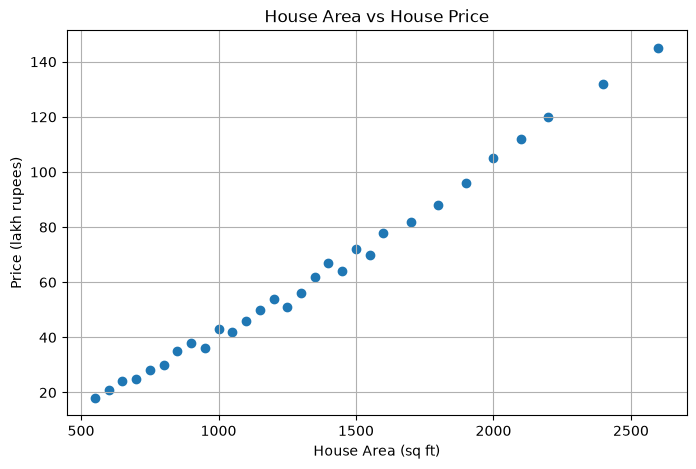

In [4]:
plt.figure(figsize=(8, 5))

plt.scatter(df["area_sqft"], df["price_lakh"])

plt.xlabel("House Area (sq ft)")
plt.ylabel("Price (lakh rupees)")
plt.title("House Area vs House Price")

plt.grid(True)
plt.show()

In [5]:

print("Checking missing values:")

print(df.isnull().sum())

print("\nChecking duplicate rows:")

print(df.duplicated().sum())


Checking missing values:
area_sqft          0
bedrooms           0
bathrooms          0
house_age_years    0
price_lakh         0
dtype: int64

Checking duplicate rows:
0


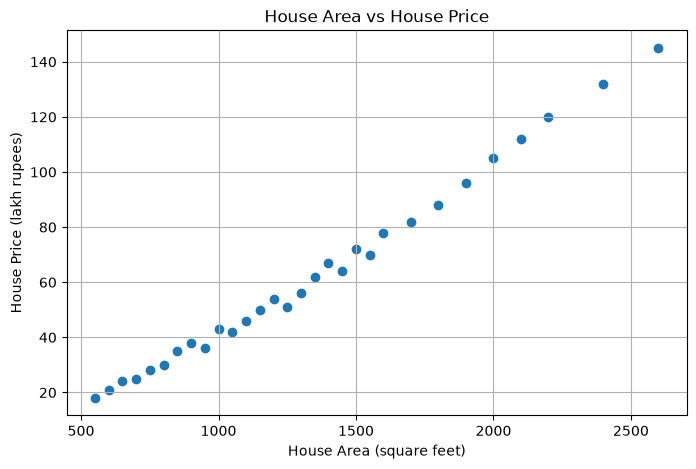

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(df["area_sqft"], df["price_lakh"])

plt.xlabel("House Area (square feet)")
plt.ylabel("House Price (lakh rupees)")

plt.title("House Area vs House Price")

plt.grid(True)

plt.show()


In [7]:

X = df[
    [
        "area_sqft",
        "bedrooms",
        "bathrooms",
        "house_age_years"
    ]
]

y = df["price_lakh"]

print("House details:")
display(X.head())

print("Prices to predict:")
display(y.head())


House details:


,area_sqft,bedrooms,bathrooms,house_age_years
0,550,1,1,15
1,600,1,1,10
2,650,1,1,8
3,700,2,1,18
4,750,2,1,12


Prices to predict:


0    18
1    21
2    24
3    25
4    28
Name: price_lakh, dtype: int64

In [8]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training houses:", len(X_train))
print("Testing houses:", len(X_test))


Training houses: 24
Testing houses: 6


In [9]:

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("My first Machine Learning model is trained!")


My first Machine Learning model is trained!


In [10]:

y_pred = model.predict(X_test)

print("Predicted prices:")
print(y_pred)

print("\nActual prices:")
print(y_test.values)


Predicted prices:
[115.75334603  60.53568776  89.88003565  64.75301562  37.70772403
  42.8457076 ]

Actual prices:
[120  56  88  67  36  43]


In [11]:

from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2), "lakh")


Mean Absolute Error: 2.46 lakh


In [12]:

import pandas as pd

new_house = pd.DataFrame({
    "area_sqft": [1200],
    "bedrooms": [3],
    "bathrooms": [2],
    "house_age_years": [5]
})

predicted_price = model.predict(new_house)

print(
    "Estimated house price:",
    round(predicted_price[0], 2),
    "lakh rupees"
)


Estimated house price: 53.97 lakh rupees


In [13]:

from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2), "lakh")
print("R-squared Score:", round(r2, 3))


Mean Squared Error: 8.36
Root Mean Squared Error: 2.89 lakh
R-squared Score: 0.99


In [14]:

import joblib

joblib.dump(model, "../house_price_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [15]:

loaded_model = joblib.load("../house_price_model.joblib")

test_house = pd.DataFrame({
    "area_sqft": [1200],
    "bedrooms": [3],
    "bathrooms": [2],
    "house_age_years": [5]
})

print(
    "Predicted price:",
    round(loaded_model.predict(test_house)[0], 2),
    "lakh"
)


Predicted price: 53.97 lakh
